# C30: thử loss MAE và mô hình bổ sung cho ensemble

Người thực hiện: Huy. Ngày thiết kế: 22/11/2026. Vai trò: thí nghiệm bổ sung, chưa thay mô hình đã chốt.

Câu hỏi: có thể giảm sai số bằng mô hình học loss khác hoặc tạo dự đoán bổ sung cho RF/XGBoost không? Giữ C30, cohort đủ history và ba fold FE; không đổi cleaning hay tập giờ. Có 5 cấu hình mô hình cố định, không gọi đây là cuộc tuning ngang ngân sách giữa các thuật toán. HistGB squared/absolute chỉ khác loss để đối chứng trong cùng họ mô hình.

Mỗi mô hình mới được xét với tỷ trọng 25%, 50% hoặc 100%; phần còn lại dùng ensemble RF/XGBoost 50/50 đã có. Chọn một trong 15 phương án cùng đối chứng bằng MAE trung bình fold, rồi RMSE trung bình fold, rồi tên phương án. Chỉ phương án thắng OOF được chấm validation; nếu đối chứng thắng, không fit mô hình mới để dò validation.

Validation đã được xem nhiều lần; đây là thử nghiệm thăm dò, không phải kiểm chứng độc lập. History dùng quan sát quá khứ theo dự đoán tuần tự và giả định thời tiết cùng giờ đã biết. Không dùng test.

Tài liệu phương pháp: [HistGradientBoosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html), [ExtraTrees](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesRegressor.html), [XGBoost objectives](https://xgboost.readthedocs.io/en/stable/parameter.html#learning-task-parameters).

## 1. Đọc giao thức và xác định ngân sách

Dùng OOF RF/XGBoost đã lưu làm đối chứng và kiểm tra lại cohort, fold, mục tiêu trước khi dùng. Không huấn luyện lại thành phần đối chứng. Các hàm tiền xử lý vẫn từ prepare_fold.

In [1]:
from pathlib import Path
import sys,json,time,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor
from threadpoolctl import threadpool_limits, threadpool_info
from importlib.metadata import version
from IPython.display import Markdown,display

project_root = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'data/preprocessed/hourly_unfilled.csv').is_file())
if str(project_root) not in sys.path:sys.path.insert(0,str(project_root))
from src import feature_experiments as fe
from src.features import CONFIG_C,add_time_features,add_weather_features,add_history_features,has_history
from src.evaluation import regression_metrics,bootstrap_mae_difference

output_dir=project_root/'experiments/22-11-2026_Huy_C30_MAE_Diversity/outputs'
output_dir.mkdir(exist_ok=True)
old_dir=project_root/'experiments/21-11-2026_Huy_C30_OOF/outputs'
old_selection=json.loads((old_dir/'selected_weights.json').read_text('utf-8'))
source_config_path=project_root/old_selection['parameter_source']
source_config=json.loads(source_config_path.read_text('utf-8'))
context=fe.load_protocol(project_root)
assert fe.frame_hash(context['cohort'][['date_time','traffic_volume']])==old_selection['cohort_hash']
reference_oof=pd.read_csv(old_dir/'oof_predictions.csv',parse_dates=['date_time'],float_precision='round_trip').set_index('date_time')
assert reference_oof.index.is_unique
old_manifest=pd.read_csv(old_dir/'fold_manifest.csv')
assert context['manifest']['score_hash'].tolist()==old_manifest['score_hash'].tolist()
assert context['manifest']['fit_hash'].tolist()==old_manifest['fit_hash'].tolist()
display(context['manifest'][['fold','fit_start','fit_end','score_start','score_end','n_fit','n']])

,fold,fit_start,fit_end,score_start,score_end,n_fit,n
0,1,2012-10-09 09:00:00,2013-08-05 19:00:00,2013-08-05 20:00:00,2015-07-12 06:00:00,5628,5625
1,2,2012-10-09 09:00:00,2015-07-12 06:00:00,2015-07-12 07:00:00,2016-09-07 17:00:00,11253,5625
2,3,2012-10-09 09:00:00,2016-09-07 17:00:00,2016-09-07 18:00:00,2017-05-10 04:00:00,16878,5625


## 2. Khóa cấu hình trước khi fit

HistGB tắt early stopping để không tự chia ngẫu nhiên phần validation nội bộ; số vòng cố định. HistGB dùng giới hạn 4 luồng được khai báo; ExtraTrees và XGBoost dùng n_jobs=4 của estimator, không áp giới hạn luồng bên ngoài. Hai HistGB chỉ khác loss; XGBoost MAE giữ tham số Claude và đổi objective. Các tổ hợp được lưu trước khi tính điểm.

In [2]:
hist_common=dict(max_iter=300,learning_rate=0.05,max_leaf_nodes=31,min_samples_leaf=20,
                 l2_regularization=1.0,early_stopping=False,categorical_features=None,random_state=42)
xgb_params={k.removeprefix('model__'):v for k,v in old_selection['model_params']['XGBoost'].items()}
xgb_params.update(objective='reg:absoluteerror',tree_method='hist',n_jobs=4,random_state=42,eval_metric='mae')
candidates={
    'HistGB_squared':HistGradientBoostingRegressor(loss='squared_error',**hist_common),
    'HistGB_MAE':HistGradientBoostingRegressor(loss='absolute_error',**hist_common),
    'ExtraTrees_leaf2':ExtraTreesRegressor(n_estimators=200,min_samples_leaf=2,max_features=0.8,random_state=42,n_jobs=4),
    'ExtraTrees_leaf5':ExtraTreesRegressor(n_estimators=200,min_samples_leaf=5,max_features=1.0,random_state=42,n_jobs=4),
    'XGBoost_MAE':XGBRegressor(**xgb_params),
}
NEW_WEIGHTS=(0.25,0.5,1.0)
candidate_specs=[]
for name,estimator in candidates.items():
    parameters=estimator.get_params()
    parameters={k:('NaN (library default)' if isinstance(v,float) and np.isnan(v) else v) for k,v in parameters.items()}
    candidate_specs.append({'model':name,'params':parameters,'n':len(context['cohort'])})
plan={'configs':candidate_specs,'new_model_weights':NEW_WEIGHTS,'n_cv_fits':len(candidates)*len(context['folds']),
      'n_selection_options':1+len(candidates)*len(NEW_WEIGHTS),'features':list(CONFIG_C),
      'cohort_hash':old_selection['cohort_hash'],'folds':context['manifest'].to_dict('records'),
      'data_sha256':context['metadata']['data_sha256'],'seed':42,
      'selection_rule':'mean fold MAE, mean fold RMSE, option ID',
      'histgb_thread_limit':4,'other_estimators_external_thread_limit':None,
      'versions':{name:version(name) for name in ['numpy','pandas','scikit-learn','xgboost']},
      'validation_used_for_selection':False,'test_evaluated':False}
(output_dir/'plan.json').write_text(json.dumps(plan,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
display(pd.DataFrame([{'model':r['model'],'n':r['n'],'params':str(r['params'])} for r in candidate_specs]))
print('Số fit CV đã chốt:',plan['n_cv_fits'],'; số phương án xét OOF:',plan['n_selection_options'])

Số fit CV đã chốt: 15 ; số phương án xét OOF: 16


,model,n,params
0,HistGB_squared,22503,"{'categorical_features': None, 'early_stopping..."
1,HistGB_MAE,22503,"{'categorical_features': None, 'early_stopping..."
2,ExtraTrees_leaf2,22503,"{'bootstrap': False, 'ccp_alpha': 0.0, 'criter..."
3,ExtraTrees_leaf5,22503,"{'bootstrap': False, 'ccp_alpha': 0.0, 'criter..."
4,XGBoost_MAE,22503,"{'objective': 'reg:absoluteerror', 'base_score..."


## 3. Fit mô hình mới trên ba fold

Mỗi fold dùng cùng ma trận đã điền thiếu từ fold-train như FE. Lưu OOF ngay sau từng fold. Kiểm tra hash ma trận so với thí nghiệm RF/XGBoost cũ; không fit imputer trên toàn train trước CV.

In [3]:
oof_parts=[]
fit_logs=[]
for fold_number,(fit_indices,score_indices) in enumerate(context['folds'],1):
    fit=context['cohort'].iloc[fit_indices]
    score=context['cohort'].iloc[score_indices]
    X_fit,X_score,statistics=fe.prepare_fold(context['train'],context['featured'],fit.date_time,score.date_time)
    old_statistics=next(r for r in old_selection['preprocessing'] if r['fold']==fold_number)
    assert statistics['fit_matrix_hash']==old_statistics['fit_matrix_hash']
    assert statistics['score_matrix_hash']==old_statistics['score_matrix_hash']
    reference=reference_oof.loc[score.date_time]
    np.testing.assert_array_equal(reference.y_true.to_numpy(),score.traffic_volume.to_numpy())
    assert reference['fold'].eq(fold_number).all()
    frame=pd.DataFrame({'fold':fold_number,'date_time':score.date_time.to_numpy(),'y_true':score.traffic_volume.to_numpy(),
                        'baseline_50_50':0.5*(reference['Random Forest'].to_numpy()+reference['XGBoost'].to_numpy())})
    fit_matrix=np.ascontiguousarray(X_fit[CONFIG_C],dtype='float32')
    score_matrix=np.ascontiguousarray(X_score[CONFIG_C],dtype='float32')
    for name,prototype in candidates.items():
        model=clone(prototype)
        started=time.perf_counter()
        if name.startswith('HistGB'):
            with threadpool_limits(limits=4):
                model.fit(fit_matrix,fit.traffic_volume.to_numpy())
                prediction=model.predict(score_matrix)
        else:
            model.fit(fit_matrix,fit.traffic_volume.to_numpy())
            prediction=model.predict(score_matrix)
        frame[name]=np.clip(prediction,0,None).astype('float64')
        fit_logs.append({'fold':fold_number,'model':name,'n_train':len(fit),'n':len(score),
                         'elapsed_seconds':time.perf_counter()-started,
                         **regression_metrics(score.traffic_volume,frame[name])})
        pd.DataFrame(fit_logs).to_csv(output_dir/'base_model_fold_scores.csv',index=False)
        print(f'Fold {fold_number}, {name}: MAE={fit_logs[-1]["MAE"]:.3f}',flush=True)
    oof_parts.append(frame)
    pd.concat(oof_parts,ignore_index=True).to_csv(output_dir/'oof_predictions.csv',index=False,float_format='%.17g')
oof=pd.concat(oof_parts,ignore_index=True)
assert oof.date_time.is_unique and len(oof)==len(reference_oof)
display(pd.DataFrame(fit_logs).round(3))

Fold 1, HistGB_squared: MAE=236.027
Fold 1, HistGB_MAE: MAE=228.307
Fold 1, ExtraTrees_leaf2: MAE=217.930
Fold 1, ExtraTrees_leaf5: MAE=223.006
Fold 1, XGBoost_MAE: MAE=219.884
Fold 2, HistGB_squared: MAE=258.599
Fold 2, HistGB_MAE: MAE=254.794
Fold 2, ExtraTrees_leaf2: MAE=245.295
Fold 2, ExtraTrees_leaf5: MAE=249.648
Fold 2, XGBoost_MAE: MAE=245.241
Fold 3, HistGB_squared: MAE=231.470
Fold 3, HistGB_MAE: MAE=221.900
Fold 3, ExtraTrees_leaf2: MAE=222.507
Fold 3, ExtraTrees_leaf5: MAE=222.119
Fold 3, XGBoost_MAE: MAE=219.845


,fold,model,n_train,n,elapsed_seconds,MAE,RMSE,R2
0,1,HistGB_squared,5628,5625,4.826,236.027,387.116,0.962
1,1,HistGB_MAE,5628,5625,6.453,228.307,396.973,0.960
2,1,ExtraTrees_leaf2,5628,5625,4.895,217.930,375.020,0.964
3,1,ExtraTrees_leaf5,5628,5625,4.086,223.006,381.968,0.963
4,1,XGBoost_MAE,5628,5625,2.981,219.884,380.852,0.963
5,2,HistGB_squared,11253,5625,5.813,258.599,447.386,0.948
6,2,HistGB_MAE,11253,5625,8.639,254.794,449.713,0.947
7,2,ExtraTrees_leaf2,11253,5625,8.296,245.295,419.292,0.954
8,2,ExtraTrees_leaf5,11253,5625,7.654,249.648,431.892,0.951
9,2,XGBoost_MAE,11253,5625,3.395,245.241,426.991,0.952


## 4. Chọn một phương án bằng OOF

Tỷ trọng mới 25% nghĩa 75% ensemble cũ + 25% mô hình mới. Xét các tỷ trọng đã chốt, không dò thêm theo validation. So sánh tương quan sai số chỉ để mô tả mức bổ sung; không dùng nó thay MAE. Điểm OOF của phương án thắng có thiên lệch do được dùng để chọn.

In [4]:
option_specs=[{'option':'Baseline_50_50','model':None,'new_weight':0.0}]
for name in candidates:
    for alpha in NEW_WEIGHTS:
        option_specs.append({'option':f'{name}__new_{alpha:.2f}','model':name,'new_weight':alpha})
option_rows=[]
for spec in option_specs:
    for fold_number,frame in oof.groupby('fold'):
        prediction=frame.baseline_50_50 if spec['model'] is None else (
            (1-spec['new_weight'])*frame.baseline_50_50+spec['new_weight']*frame[spec['model']])
        option_rows.append({**spec,'fold':fold_number,'n':len(frame),**regression_metrics(frame.y_true,prediction)})
option_scores=pd.DataFrame(option_rows)
summary=option_scores.groupby('option',as_index=False).agg(n=('n','sum'),MAE_mean=('MAE','mean'),MAE_std=('MAE','std'),RMSE_mean=('RMSE','mean'),R2_mean=('R2','mean'))
summary=summary.sort_values(['MAE_mean','RMSE_mean','option']).reset_index(drop=True)
chosen=next(r for r in option_specs if r['option']==summary.iloc[0].option)
baseline_cv=summary.loc[summary.option.eq('Baseline_50_50')].iloc[0]
display(summary.round(4))
base_error=oof.baseline_50_50-oof.y_true
diversity=pd.DataFrame([{'model':name,'n':len(oof),'error_correlation_with_baseline':np.corrcoef(base_error,oof[name]-oof.y_true)[0,1]} for name in candidates])
display(diversity.round(4))
selection={**chosen,'OOF_MAE':float(summary.iloc[0].MAE_mean),'baseline_OOF_MAE':float(baseline_cv.MAE_mean),
           'selection_rule':plan['selection_rule'],'plan_sha256':hashlib.sha256((output_dir/'plan.json').read_bytes()).hexdigest(),
           'candidate_params':None if chosen['model'] is None else next(r['params'] for r in candidate_specs if r['model']==chosen['model']),
           'validation_used_for_selection':False,'validation_previously_seen':True}
(output_dir/'selected_option.json').write_text(json.dumps(selection,ensure_ascii=False,indent=2),encoding='utf-8')
option_scores.to_csv(output_dir/'option_fold_scores.csv',index=False)
summary.to_csv(output_dir/'oof_ranking.csv',index=False)
diversity.to_csv(output_dir/'residual_diversity.csv',index=False)
context['manifest'].to_csv(output_dir/'fold_manifest.csv',index=False)
print('Đã cố định phương án trước validation:',chosen)

Đã cố định phương án trước validation: {'option': 'ExtraTrees_leaf2__new_0.50', 'model': 'ExtraTrees_leaf2', 'new_weight': 0.5}


,option,n,MAE_mean,MAE_std,RMSE_mean,R2_mean
0,ExtraTrees_leaf2__new_0.50,16875,225.2726,14.0229,372.0358,0.9638
1,ExtraTrees_leaf2__new_0.25,16875,225.6084,13.5121,371.3778,0.9640
2,XGBoost_MAE__new_0.50,16875,225.7549,14.2254,375.5289,0.9631
3,XGBoost_MAE__new_0.25,16875,225.9970,13.7692,373.4784,0.9635
4,HistGB_MAE__new_0.25,16875,226.2298,14.3786,374.2104,0.9634
5,ExtraTrees_leaf5__new_0.25,16875,226.8521,13.5226,373.5993,0.9635
6,HistGB_MAE__new_0.50,16875,227.1093,15.6236,379.0542,0.9624
7,Baseline_50_50,16875,227.2410,13.0267,372.7650,0.9637
8,ExtraTrees_leaf5__new_0.50,16875,227.4641,14.1774,376.1075,0.9630
9,XGBoost_MAE__new_1.00,16875,228.3234,14.6515,383.5466,0.9615


,model,n,error_correlation_with_baseline
0,HistGB_squared,16875,0.9494
1,HistGB_MAE,16875,0.9331
2,ExtraTrees_leaf2,16875,0.9575
3,ExtraTrees_leaf5,16875,0.9655
4,XGBoost_MAE,16875,0.9728


## 5. Kiểm tra lợi ích theo fold và vẽ kết quả OOF

Báo chênh MAE theo từng fold để thấy lợi ích có tập trung vào một giai đoạn hay không. Không coi ba fold là ba khoảng lịch bằng nhau.

,fold,n,MAE_baseline,MAE_selected,MAE_reduction,RMSE_reduction
0,1,5625,219.4087,215.4355,3.9733,1.6975
1,2,5625,242.2786,241.3296,0.9489,0.4370
2,3,5625,220.0357,219.0527,0.9830,0.0532


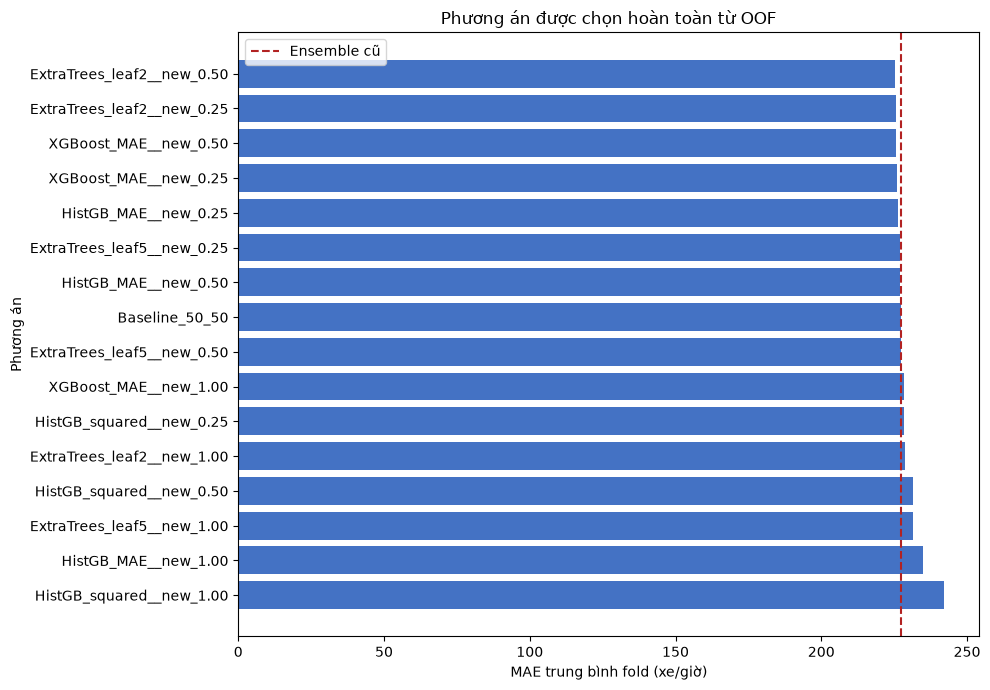

Đọc biểu đồ này như sau: thanh ngắn hơn có MAE OOF thấp hơn; đường đỏ là mốc 50/50 cũ. Ngân sách nhỏ và một seed chưa đủ xếp hạng toàn diện các thuật toán.

In [5]:
base_folds=option_scores.loc[option_scores.option.eq('Baseline_50_50')].set_index('fold')
selected_folds=option_scores.loc[option_scores.option.eq(chosen['option'])].set_index('fold')
fold_comparison=pd.DataFrame({'n':base_folds.n,'MAE_baseline':base_folds.MAE,'MAE_selected':selected_folds.MAE,
    'MAE_reduction':base_folds.MAE-selected_folds.MAE,'RMSE_reduction':base_folds.RMSE-selected_folds.RMSE}).reset_index()
display(fold_comparison.round(4))
fold_comparison.to_csv(output_dir/'oof_fold_comparison.csv',index=False)
fig,ax=plt.subplots(figsize=(10,7))
ax.barh(summary.option,summary.MAE_mean,color='#4472C4');ax.invert_yaxis()
ax.axvline(baseline_cv.MAE_mean,color='firebrick',linestyle='--',label='Ensemble cũ')
ax.set(xlabel='MAE trung bình fold (xe/giờ)',ylabel='Phương án',title='Phương án được chọn hoàn toàn từ OOF')
ax.legend();fig.tight_layout();fig.savefig(output_dir/'oof_mae.png',dpi=150);plt.show()
display(Markdown('Đọc biểu đồ này như sau: thanh ngắn hơn có MAE OOF thấp hơn; đường đỏ là mốc 50/50 cũ. Ngân sách nhỏ và một seed chưa đủ xếp hạng toàn diện các thuật toán.'))

## 6. Chỉ refit phương án thắng OOF rồi chấm validation

Giữ tham số và tỷ trọng đã lưu. Nếu phương án có mô hình mới, fit duy nhất mô hình đó trên toàn cohort train; hai thành phần RF/XGBoost dùng lại dự đoán đã lưu. Kiểm tra dữ liệu prefix không đổi. Không chấm các phương án thua OOF để chọn lại bằng validation.

In [6]:
frozen=json.loads((output_dir/'selected_option.json').read_text('utf-8'))
assert frozen['option']==chosen['option']
csv_path=project_root/'data/preprocessed/hourly_unfilled.csv'
n_total=len(pd.read_csv(csv_path,usecols=['date_time']))
train_stop,validation_stop=n_total*70//100,n_total*85//100
hourly=pd.read_csv(csv_path,nrows=validation_stop,keep_default_na=False,na_values={'temp':[''],'rain_1h':['']},float_precision='round_trip')
hourly['date_time']=pd.to_datetime(hourly.date_time,format='%Y-%m-%d %H:%M:%S')
assert fe.frame_hash(hourly)==source_config['input_prefix_hash']
featured=add_history_features(add_weather_features(add_time_features(hourly)))
fit=featured.iloc[:train_stop].copy();fit=fit.loc[has_history(fit)].copy()
score=featured.iloc[train_stop:].copy();score=score.loc[has_history(score)].copy()
assert fe.frame_hash(fit[['date_time','traffic_volume']])==old_selection['cohort_hash']
cached=pd.read_csv(source_config_path.parent/'validation_predictions.csv',parse_dates=['date_time'],float_precision='round_trip')
cached['XGBoost']=cached['XGBoost'].astype('float32').astype('float64')
np.testing.assert_array_equal(score.date_time.to_numpy(),cached.date_time.to_numpy())
np.testing.assert_array_equal(score.traffic_volume.to_numpy(),cached.y_true.to_numpy())
baseline_validation=cached['Ensemble RF + XGBoost (50/50)'].to_numpy()
validation_predictions={'Baseline 50/50':baseline_validation}
if frozen['model'] is not None:
    X_fit,X_score,full_stats=fe.prepare_fold(hourly,featured,fit.date_time,score.date_time)
    assert full_stats['fit_matrix_hash']==source_config['preprocessing']['fit_matrix_hash']
    assert full_stats['score_matrix_hash']==source_config['preprocessing']['score_matrix_hash']
    model=clone(candidates[frozen['model']])
    if frozen['model'].startswith('HistGB'):
        with threadpool_limits(limits=4):
            model.fit(np.ascontiguousarray(X_fit[CONFIG_C],dtype='float32'),fit.traffic_volume.to_numpy())
            new_prediction=np.clip(model.predict(np.ascontiguousarray(X_score[CONFIG_C],dtype='float32')),0,None).astype('float64')
    else:
        model.fit(np.ascontiguousarray(X_fit[CONFIG_C],dtype='float32'),fit.traffic_volume.to_numpy())
        new_prediction=np.clip(model.predict(np.ascontiguousarray(X_score[CONFIG_C],dtype='float32')),0,None).astype('float64')
    validation_predictions['New model (diagnostic)']=new_prediction
    validation_predictions['Selected by OOF']=(1-frozen['new_weight'])*baseline_validation+frozen['new_weight']*new_prediction
else:
    validation_predictions['Selected by OOF']=baseline_validation.copy()
validation_metrics=pd.DataFrame([{'model':name,'n':len(score),**regression_metrics(score.traffic_volume,pred)} for name,pred in validation_predictions.items()])
display(validation_metrics.round({'MAE':3,'RMSE':3,'R2':6}))
validation_metrics.to_csv(output_dir/'validation_metrics.csv',index=False)
pd.DataFrame({'date_time':score.date_time.to_numpy(),'y_true':score.traffic_volume.to_numpy(),**validation_predictions}).to_csv(output_dir/'validation_predictions.csv',index=False,float_format='%.17g')

,model,n,MAE,RMSE,R2
0,Baseline 50/50,6050,193.810,316.085,0.974109
1,New model (diagnostic),6050,191.216,319.854,0.973488
2,Selected by OOF,6050,190.190,313.527,0.974527


## 7. Kết luận và hạn chế

Lợi ích được tính trên cùng giờ. Bootstrap theo ngày chỉ là mô tả thăm dò trên validation đã xem nhiều lần; không làm biến mất thiên lệch lựa chọn qua nhiều thí nghiệm. Nếu phương án mới không cải thiện, giữ nguyên đối chứng và ghi kết quả âm; không đổi thiết kế sau khi nhìn validation.

In [7]:
indexed=validation_metrics.set_index('model')
gain=float(indexed.loc['Baseline 50/50','MAE']-indexed.loc['Selected by OOF','MAE'])
rmse_gain=float(indexed.loc['Baseline 50/50','RMSE']-indexed.loc['Selected by OOF','RMSE'])
bootstrap=bootstrap_mae_difference(score,baseline_validation,validation_predictions['Selected by OOF'],n_boot=2000,seed=42)
display(pd.DataFrame([{'n':len(score),**bootstrap}]).round(4))
decision=('Phương án chọn từ OOF giảm MAE validation trong lượt này; giữ là ứng viên bổ sung, chưa thay pipeline chính hay kết luận từ test.' if gain>0 else 'Chưa cải thiện MAE validation; giữ ensemble 50/50 cũ.')
assessment=(f'Đã xét {len(candidates)} cấu hình mô hình mới và {plan["n_selection_options"]} phương án OOF, '
    f'dùng {plan["n_cv_fits"]} fit trên cùng ba fold và {len(oof):,} giờ OOF. '
    f'Chọn {frozen["option"]}; MAE OOF {frozen["OOF_MAE"]:.4f}, đối chứng {frozen["baseline_OOF_MAE"]:.4f} xe/giờ. '
    f'Trên {len(score):,} giờ validation, MAE đối chứng {indexed.loc["Baseline 50/50","MAE"]:.4f}, '
    f'phương án mới {indexed.loc["Selected by OOF","MAE"]:.4f} xe/giờ; giảm {gain:.4f} xe/giờ. '
    f'Chênh RMSE (cũ trừ mới) {rmse_gain:.4f} xe/giờ. {decision} '
    'Đây là thử nghiệm thăm dò sau khi đã xem validation; một seed, ngân sách nhỏ và dùng OOF để chọn giới hạn kết luận. Không chấm test.')
display(Markdown(assessment))
(output_dir/'assessment.md').write_text(assessment+'\n',encoding='utf-8')
(output_dir/'bootstrap.json').write_text(json.dumps(bootstrap,indent=2),encoding='utf-8')
(output_dir/'runtime_threadpools.json').write_text(json.dumps(threadpool_info(),indent=2),encoding='utf-8')
print('Kết quả được lưu riêng:',output_dir.relative_to(project_root))

Kết quả được lưu riêng: experiments\22-11-2026_Huy_C30_MAE_Diversity\outputs


,n,chenh_lech_MAE,CI95_thap,CI95_cao,so_ngay
0,6050,3.6203,1.6303,5.7975,255


Đã xét 5 cấu hình mô hình mới và 16 phương án OOF, dùng 15 fit trên cùng ba fold và 16,875 giờ OOF. Chọn ExtraTrees_leaf2__new_0.50; MAE OOF 225.2726, đối chứng 227.2410 xe/giờ. Trên 6,050 giờ validation, MAE đối chứng 193.8102, phương án mới 190.1900 xe/giờ; giảm 3.6203 xe/giờ. Chênh RMSE (cũ trừ mới) 2.5582 xe/giờ. Phương án chọn từ OOF giảm MAE validation trong lượt này; giữ là ứng viên bổ sung, chưa thay pipeline chính hay kết luận từ test. Đây là thử nghiệm thăm dò sau khi đã xem validation; một seed, ngân sách nhỏ và dùng OOF để chọn giới hạn kết luận. Không chấm test.